# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN CUSTOMER CHURN

## 1. Giới thiệu và phạm vi thực nghiệm

Notebook giữ baseline, tuning, CV, OOF, test evaluation và các phân tích nghiệp vụ
cho KNN, Decision Tree và Gaussian Naive Bayes.

**Trạng thái T8:** chỉ static cleanup, không chạy notebook, tuning, CV hoặc training.
Outputs và execution counts đã lưu được giữ nguyên; chúng có thể thuộc các lần
chạy khác nhau và chưa xác nhận code sau cleanup. Các số liệu dẫn từ outputs đã
lưu trong nhận xét không phải kết quả tính lại. T9 sẽ xác nhận runtime và đồng bộ outputs.

Giữ split 80/20 stratified, seed 42 và ba thuật toán. Tuning/CV/OOF dùng raw training
qua Pipeline. Cost-sensitive 5:1 chọn threshold từ OOF training. Expected Net Benefit
là kịch bản riêng. Risk × Value giữ phân vị 70% OOF training probabilities và median
MonthlyCharges của training, rồi áp dụng cutoff đã khóa lên test.

Trình tự: dữ liệu → hàm chung → baseline/tuning → CV → OOF/cost sensitivity
→ Expected Net Benefit → test → error analysis → feature importance → Risk × Value.

## 2. Imports và cấu hình

In [188]:
# Xử lý dữ liệu
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Trực quan hóa
import matplotlib.pyplot as plt

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model selection
from sklearn.model_selection import (
    StratifiedKFold, 
    cross_validate,
    GridSearchCV,
    train_test_split,
    cross_val_predict
)

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from IPython.display import display

from sklearn.base import clone # 
from sklearn.pipeline import Pipeline # 

In [189]:
# Hai thiết lập CV khác nhau được giữ nguyên như thí nghiệm ban đầu.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc"
}
cost_scenarios = [1, 2, 5, 10]
cost_fn_test, cost_fp_test = 5, 1
threshold_grid = np.arange(0.10, 0.91, 0.05)

# Giả định minh họa riêng cho Expected Net Benefit; không phải dữ liệu thực tế.
RETENTION_COST = 10
SAVED_CUSTOMER_VALUE = 100
RETENTION_SUCCESS_RATE = 0.30
# locked_thresholds được tạo sau OOF cost-sensitive optimization ở mục 7.
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"
]

## 3. Dữ liệu và kiểm tra tính nhất quán

Processed artifacts được giữ cho baseline classifiers và kiểm tra alignment.
Các tuned models dùng X_train_raw, y_train_raw trong GridSearchCV, Final CV và OOF.
Mỗi model là Pipeline preprocessor → clf: preprocessing chỉ fit training fold và
chỉ transform validation fold. Pipeline tốt nhất được refit trên toàn training
và nhận X_test_raw để đánh giá. Test không tham gia fit/tuning/CV/threshold selection.

In [190]:
DATA_DIR = Path("../data") if Path("../data/X_train_processed.npy").is_file() else Path("data")

X_train = np.load(DATA_DIR / "X_train_processed.npy")
X_test = np.load(DATA_DIR / "X_test_processed.npy")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

feature_names = joblib.load(
    DATA_DIR / "feature_names.pkl"
)

In [191]:
print(f"Kích thước dữ liệu")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == len(feature_names)

print("Shape alignment OK")

print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

Kích thước dữ liệu
X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634,)
y_test : (1409,)
Number of features: 40
Shape alignment OK
Train labels: [0 1]
Test labels : [0 1]
TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64
NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


#### Nhận xét

Dữ liệu sau tiền xử lý gồm **40 đặc trưng** và được chia thành
**5.634 mẫu huấn luyện** và **1.409 mẫu kiểm thử**.

Phân bố nhãn cho thấy số khách hàng không Churn lớn hơn số khách hàng Churn.
Do đó, ngoài Accuracy, các chỉ số **Precision, Recall và F1-score**
cần được xem xét khi đánh giá mô hình.

In [192]:
# Đọc lại dữ liệu gốc
df_raw = pd.read_csv(DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Xử lý TotalCharges giống bước preprocessing ban đầu
df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"],
    errors="coerce"
)

df_raw["TotalCharges"] = df_raw["TotalCharges"].fillna(0)

# Target
df_raw["Churn"] = df_raw["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Features và target giống notebook preprocessing
X_raw = df_raw.drop(columns=["customerID", "Churn"])
y_raw = df_raw["Churn"]

# Tái tạo chính xác train/test split
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    stratify=y_raw,
    random_state=42
)

print("X_test_raw shape :", X_test_raw.shape)
print("X_test shape     :", X_test.shape)
print("y_test_raw shape :", y_test_raw.shape)
print("y_test shape     :", y_test.shape)
# Chỉ transform bằng pipeline đã lưu; không fit lại preprocessing.
preprocessing_pipeline = joblib.load(DATA_DIR / "preprocessing_pipeline.pkl")
assert np.array_equal(y_train_raw.to_numpy(), np.asarray(y_train).ravel())
assert np.array_equal(y_test_raw.to_numpy(), np.asarray(y_test).ravel())
assert np.array_equal(
    preprocessing_pipeline.named_steps["preprocessor"].get_feature_names_out(),
    feature_names
)
for raw_part, processed_part in [(X_train_raw, X_train), (X_test_raw, X_test)]:
    transformed_part = preprocessing_pipeline.transform(raw_part)
    if hasattr(transformed_part, "toarray"):
        transformed_part = transformed_part.toarray()
    assert transformed_part.shape == processed_part.shape
    np.testing.assert_allclose(transformed_part, processed_part, rtol=1e-7, atol=1e-9)
print("Raw/processed features, labels and feature names aligned.")

X_test_raw shape : (1409, 19)
X_test shape     : (1409, 40)
y_test_raw shape : (1409,)
y_test shape     : (1409,)
Raw/processed features, labels and feature names aligned.


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimato

In [193]:
# Lấy cấu hình preprocessing từ pipeline của Role 2
# clone() tạo một preprocessor mới CHƯA được fit
preprocessor = clone(
    preprocessing_pipeline.named_steps["preprocessor"]
)
print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 OneHotEncoder(drop='if_binary',
                                               handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


Dữ liệu thô giữ nguyên index và thứ tự từ cùng phép chia stratified.
Các kiểm tra trên chỉ xác minh artifact đã lưu; không huấn luyện hoặc fit lại transformer.
Nếu kiểm tra thất bại, cần xác minh artifact trước khi tiếp tục phân tích khách hàng.

## 4. Hàm đánh giá và phân tích dùng chung

Để đảm bảo các mô hình được đánh giá theo cùng một quy trình,
các hàm đánh giá được định nghĩa một lần và tái sử dụng cho KNN,
Decision Tree và Naive Bayes.

Các chỉ số chính gồm:

- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ dữ liệu.
- **Precision:** mức độ chính xác của các dự đoán Churn.
- **Recall:** khả năng phát hiện khách hàng thực sự Churn.
- **F1-score:** cân bằng giữa Precision và Recall.
- **Confusion Matrix:** thể hiện số lượng TN, FP, FN và TP.

Các metric được dùng thống nhất cho cả ba thuật toán: 
| Metric    | Câu hỏi nó trả lời                                          |
| --------- | ----------------------------------------------------------- |
| Accuracy  | Tổng thể model đoán đúng bao nhiêu %?                       |
| Precision | Những người model báo churn, bao nhiêu người thực sự churn? |
| Recall    | Những người thực sự churn, model bắt được bao nhiêu?        |
| F1-score  | Cân bằng Precision và Recall                                |
| ROC-AUC   | Model phân biệt churn và non-churn tốt đến đâu?             |

In [194]:
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    # Tính các metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    # In metrics
    print(f"===== {model_name} =====")
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1-score : {results['F1-score']:.4f}")
    print(f"ROC-AUC  : {results['ROC-AUC']:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return results


def compare_model_metrics(baseline_result, tuned_result):
    metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

    comparison_table = pd.DataFrame({
        "Baseline": [baseline_result[m] for m in metrics],
        "Tuned": [tuned_result[m] for m in metrics]
    }, index=metrics)

    comparison_table["Improvement"] = (
        comparison_table["Tuned"] - comparison_table["Baseline"]
    )

    return comparison_table.round(4)

def compare_confusion_matrix(y_test, y_pred_baseline, y_pred_tuned):
    cm_baseline = confusion_matrix(y_test, y_pred_baseline)
    cm_tuned = confusion_matrix(y_test, y_pred_tuned)

    tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
    tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()

    cm_comparison = pd.DataFrame({
        "Baseline": [tn_b, fp_b, fn_b, tp_b],
        "Tuned": [tn_t, fp_t, fn_t, tp_t]
    }, index=["TN", "FP", "FN", "TP"])

    cm_comparison["Change"] = (
        cm_comparison["Tuned"] - cm_comparison["Baseline"]
    )

    return cm_comparison


def classify_prediction(y_true, y_pred):
    if y_true == 1 and y_pred == 1:
        return "TP"
    elif y_true == 0 and y_pred == 0:
        return "TN"
    elif y_true == 0 and y_pred == 1:
        return "FP"
    else:
        return "FN"

In [195]:
def metrics_at_threshold(y_true, probabilities, threshold, cost_fn=5, cost_fp=1):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Total Cost": fn * cost_fn + fp * cost_fp
    }


def threshold_analysis(y_true, probabilities, thresholds, cost_fn=5, cost_fp=1):
    return pd.DataFrame([
        metrics_at_threshold(y_true, probabilities, threshold, cost_fn, cost_fp)
        for threshold in thresholds
    ])


def categorical_error_profile(data, column, result_column="Error_Type",
                              groups=None, decimals=2):
    selected = data if groups is None else data.loc[data[result_column].isin(groups)]
    return (pd.crosstab(
        selected[result_column], selected[column], normalize="index"
    ) * 100).round(decimals)


def churn_rate_by_group(data, column, sort_by_rate=False, observed=False):
    table = (
        data.groupby(column, observed=observed)["Churn_binary"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "Churn_Rate", "count": "Customers"})
    )
    if sort_by_rate:
        table = table.sort_values("Churn_Rate", ascending=False)
    table["Churn_Rate"] *= 100
    return table

In [196]:
def segment_error_rate(data, model, feature):

    rows = []

    for category in data[feature].unique():

        segment = data[data[feature] == category]

        actual_negative = segment[
            segment["Actual_Churn"] == 0
        ]

        actual_positive = segment[
            segment["Actual_Churn"] == 1
        ]

        fp_count = (
            actual_negative[f"{model}_Result"] == "FP"
        ).sum()

        fn_count = (
            actual_positive[f"{model}_Result"] == "FN"
        ).sum()

        fp_rate = (
            fp_count / len(actual_negative)
            if len(actual_negative) > 0 else 0
        )

        fn_rate = (
            fn_count / len(actual_positive)
            if len(actual_positive) > 0 else 0
        )

        rows.append({
            feature: category,

            "Actual No Churn": len(actual_negative),
            "FP": fp_count,
            "FP Rate": fp_rate,

            "Actual Churn": len(actual_positive),
            "FN": fn_count,
            "FN Rate": fn_rate
        })

    return pd.DataFrame(rows)

In [197]:
def find_best_threshold_by_cost(
    y_true,
    y_prob,
    fn_cost=5,
    fp_cost=1,
    thresholds=None
):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.01)

    results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        cost = fn_cost * fn + fp_cost * fp

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Cost": cost,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["Cost"].idxmin()
    ]

    return best_row, results_df

In [198]:
def find_best_threshold_by_net_benefit(
    y_true,
    y_prob,
    retention_cost=10,
    saved_customer_value=100,
    retention_success_rate=0.30,
    thresholds=None
):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.01)

    results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        targeted_customers = tp + fp

        expected_saved_value = (
            tp
            * saved_customer_value
            * retention_success_rate
        )

        total_retention_cost = (
            targeted_customers
            * retention_cost
        )

        net_benefit = (
            expected_saved_value
            - total_retention_cost
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Targeted_Customers": targeted_customers,
            "Expected_Saved_Value": expected_saved_value,
            "Retention_Cost": total_retention_cost,
            "Net_Benefit": net_benefit
        })

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["Net_Benefit"].idxmax()
    ]

    return best_row, results_df

## 5. Baseline và hyperparameter tuning

Ba baseline và ba tuned models được giữ đầy đủ. GridSearchCV dùng cv=5,
scoring="f1" và raw training qua Pipeline. DT grid gồm clf__class_weight = [None,
"balanced"]; NB grid là np.logspace(-12, -1, 12). Test evaluation đặt sau CV/OOF.

### 5.1. K-Nearest Neighbors

#### Tổng quan

KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới
      ↓
① Tính khoảng cách với khách trong train
      ↓
② Tìm K người gần nhất
      ↓
③ Xem họ thuộc class 0 hay 1
      ↓
④ Majority vote
      ↓
Dự đoán Churn / No Churn

In [199]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train, y_train); # train

#### Tối ưu siêu tham số KNN

Hiệu suất của KNN phụ thuộc nhiều vào số lượng láng giềng `k`
(`n_neighbors`). Giá trị `k` quá nhỏ có thể khiến mô hình nhạy với nhiễu,
trong khi giá trị `k` quá lớn có thể làm giảm khả năng phân biệt giữa các lớp.

Trong phần này, **GridSearchCV** được sử dụng để thử nghiệm nhiều giá trị
`n_neighbors` và lựa chọn giá trị tốt nhất thông qua **5-fold cross-validation**.

Do dữ liệu Customer Churn có sự mất cân bằng giữa hai lớp,
**F1-score** được sử dụng làm tiêu chí tối ưu nhằm cân bằng giữa
Precision và Recall.

| 5W1H       | Giải thích                                                                                                                                                                           |
| ---------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **What?**  | **KNN Tuned** là mô hình K-Nearest Neighbors sau khi tối ưu siêu tham số. Trong bài này, tham số được tối ưu là `n_neighbors`, và kết quả tốt nhất là **k = 21**.                |
| **Why?**   | KNN Baseline sử dụng mặc định `k = 5`, nhưng giá trị mặc định chưa chắc phù hợp với dữ liệu Customer Churn. Tuning nhằm tìm `k` giúp mô hình nhận diện Churn tốt hơn.                |
| **When?**  | Thực hiện sau khi xây dựng KNN Baseline; đánh giá test được trình bày ở mục 8. Chỉ đánh giá trên `X_test_raw` sau khi quá trình lựa chọn `k` bằng training data hoàn tất.                                       |
| **Where?** | Trong notebook: **Mục 5.1: tuning → Mục 8: test evaluation**.                                                                                                            |
| **Who?**   | `GridSearchCV` thử các giá trị `k`; `KNeighborsClassifier` thực hiện classification; dữ liệu train dùng để tuning và test dùng để đánh giá cuối cùng.                                |
| **How?**   | Thử nhiều `k` → 5-fold CV → tính F1 cho từng cấu hình → chọn `k` tốt nhất → train best model → predict test → đánh giá Accuracy, Precision, Recall, F1, ROC-AUC và Confusion Matrix. |

In [200]:
knn_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", KNeighborsClassifier())
])

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25]
}

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(X_train_raw, y_train_raw)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__n_neighbors': [3, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate p

In [201]:
print("Best parameters:", grid_knn.best_params_)
print(f"Best CV F1-score: {grid_knn.best_score_:.4f}")

Best parameters: {'clf__n_neighbors': 21}
Best CV F1-score: 0.6056


In [202]:
best_knn = grid_knn.best_estimator_

### 5.2. Decision Tree

#### Tổng quan

##### What - DT là gì ?
DT là thuật toán học có giám sát sử dụng cấu trúc dạng cây để đưa ra quyết định dự đoán 
Mỗi nút trong cây thực hiện một điều kiện trên đặc trưng, các nhánh biểu diễn kết quả của điều kiện và các nút lá đưa ra lớp dự đoán cuối cùng

##### Why - Tại sao sử dụng DT ?
- Có khả năng mô hình hóa các đặc trưng phi tuyến tính của các đặc trưng
- Ko yêu cầu giả định về phân phối dữ liệu
- Kết quả tương đối dễ giải thích thông qua cấu trúc cây
- Có thể xác định mức độ quan trọng của các đặc trưng
- Phù hợp để so sánh với knn

Tuy nhiên, cây có nguy cơ overfitting nếu cây phát triển quá sâu. Do đó cần thực hiện hyperparmeter tuning.

##### When - Khi nào nên áp dụng DT ?
DT phù hợp các bài toán classification khi cần dự đoán nhãn dựa vào các đặc trưng và cần khả năng giải thích quyết định của mô hình

##### Where - Được áp dụng ở đâu?
Baseline dùng processed X_train/X_test. Tuned Pipeline dùng raw X_train_raw/X_test_raw.

##### Who - Các thành phần tham gia
- `DecisionTreeClassifier`: xây dựng mô hình Decision Tree.
- Training set: dùng để huấn luyện và tối ưu mô hình.
- Test set: dùng để đánh giá mô hình cuối cùng.
- GridSearchCV: được sử dụng ở bước sau để tìm hyperparameter phù hợp.

##### How – Decision Tree hoạt động như thế nào?

Decision Tree liên tục chia dữ liệu thành các nhóm dựa trên những đặc trưng
giúp phân biệt các lớp tốt nhất.

Quá trình có thể mô tả:

Data
↓
Chọn feature và điểm chia
↓
Chia dữ liệu thành các nhánh
↓
Tiếp tục chia tại các node con
↓
Leaf Node
↓
Dự đoán No Churn / Churn

Sau khi xây dựng baseline, các hyperparameter như `max_depth` sẽ được
điều chỉnh nhằm kiểm soát độ phức tạp của cây và hạn chế overfitting.

In [203]:
dt_baseline = DecisionTreeClassifier(random_state=42)

display(dt_baseline.fit(X_train, y_train))

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

#### Tối ưu siêu tham số Decision Tree

#### Decision Tree Tuning

- **What:** Tối ưu các hyperparameter kiểm soát độ phức tạp của Decision Tree.
- **Why:** Decision Tree mặc định có thể phát triển cây quá sâu và học quá sát
  training data, dẫn đến overfitting và khả năng tổng quát hóa kém.
- **When:** Thực hiện sau khi xây dựng Decision Tree Baseline; đánh giá test được trình bày ở mục 8.
- **Where:** Việc lựa chọn hyperparameter được thực hiện trên training set
  bằng cross-validation; test set không được sử dụng để lựa chọn tham số.
- **Who:** `GridSearchCV` kết hợp với `DecisionTreeClassifier` để tìm cấu hình
  phù hợp nhất.
- **How:** Thử nhiều tổ hợp hyperparameter bằng 5-fold cross-validation và
  sử dụng F1-score làm tiêu chí lựa chọn mô hình tốt nhất.

max_depth
    → cây được phép sâu bao nhiêu

min_samples_split
    → cần tối thiểu bao nhiêu mẫu để tiếp tục chia node

min_samples_leaf
    → mỗi leaf phải có tối thiểu bao nhiêu mẫu

class_weight được tuning với [None, "balanced"]; balanced weights được classifier xác định từ training portion trong mỗi lần fit.

In [204]:
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 5, 7, 10, None],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 5, 10],
    "clf__class_weight": [None, "balanced"]
}

grid_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train_raw, y_train_raw)

print("Best parameters:", grid_dt.best_params_)
print(f"Best CV F1-score: {grid_dt.best_score_:.4f}")

Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Best CV F1-score: 0.6204


In [205]:
print("max_depth:", grid_dt.best_estimator_.named_steps["clf"].max_depth)
print("min_samples_leaf:", grid_dt.best_estimator_.named_steps["clf"].min_samples_leaf)
print("min_samples_split:", grid_dt.best_estimator_.named_steps["clf"].min_samples_split)
print("class_weight:", grid_dt.best_estimator_.named_steps["clf"].class_weight)
print("criterion:", grid_dt.best_estimator_.named_steps["clf"].criterion)

best_dt = grid_dt.best_estimator_
print(best_dt)

max_depth: 3
min_samples_leaf: 1
min_samples_split: 2
criterion: gini
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                 

#### Kết quả Hyperparameter Tuning

Cấu hình DT theo output tuning đã lưu:

- class_weight = "balanced"
- criterion = "gini"
- max_depth = 3
- min_samples_leaf = 1
- min_samples_split = 2

Best CV F1-score đã lưu là 0.6204, chưa tính lại trong T8. Độ sâu giới hạn kiểm
soát độ phức tạp; balanced weights điều chỉnh ảnh hưởng mất cân bằng lớp.
T9 cần xác nhận grid_dt.best_params_.

### 5.3. Gaussian Naive Bayes

#### Naive Bayes
1. What
- Naive Bayes (NB) là thuật toán phân loại dựa trên xác suất và định lý Bayes.
- Ví dụ đơn giản, nó xử lý bằng chứng từ Contract, tenure, MonthlyCharges, TechSupport theo giả định độc lập có điều kiện, dù trong thực tế chúng có thể liên quan nhau

2. Why
- Nhanh, đơn giản, ít computational cost và tạo được xác suất dự đoán thông qua predict_proba()
- Khác với các model trên: 
    + KNN → dựa trên khoảng cách giữa các khách hàng
    + Decision Tree → dựa trên các luật chia nhánh
    + Naive Bayes → dựa trên xác suất
- Ba cách tiếp cận classification khác nhau, phù hợp với yêu cầu rubric về so sánh nhiều thuật toán và thảo luận ưu/nhược điểm, mức phù hợp với dữ liệu.

3. When 
- NB thường hữu ích khi cần một classifier nhanh, đơn giản và làm baseline/comparison model, đặc biệt khi số feature tương đối nhiều.

---
- Naive Bayes có nhiều biến thể:
    + GaussianNB
    + MultinomialNB
    + BernoulliNB
    + CategoricalNB
- Với dữ liệu hiện tại có numerical features đã scale + categorical features đã one-hot, chúng ta có thể bắt đầu bằng **GaussianNB** như một lựa chọn thực dụng cho dữ liệu đầu vào hiện tại

In [206]:
nb_baseline = GaussianNB()

display(nb_baseline.fit(X_train, y_train))

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


Sau khi xây dựng mô hình Baseline, `GridSearchCV` được sử dụng để tìm giá trị `var_smoothing` phù hợp cho Gaussian Naive Bayes.

`var_smoothing` giúp ổn định việc ước lượng phương sai trong Gaussian Naive Bayes bằng cách bổ sung một lượng nhỏ vào variance của các đặc trưng.

Quá trình tuning sử dụng 5-fold Cross-Validation (`cv=5`) trên tập training. F1-score được chọn làm tiêu chí đánh giá do dữ liệu Customer Churn bị mất cân bằng và cần cân bằng giữa Precision và Recall.

Tập test không được sử dụng trong quá trình lựa chọn hyperparameter nhằm đảm bảo đánh giá cuối cùng được thực hiện trên dữ liệu chưa được sử dụng để tối ưu mô hình.

Search space hiện tại là np.logspace(-12, -1, 12). Output đã lưu chọn var_smoothing = 0.001; T9 sẽ xác nhận lại.

In [207]:
nb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", GaussianNB())
])

param_grid_nb = {
    "clf__var_smoothing": np.logspace(-12, -1, 12)
}

grid_nb = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_nb.fit(X_train_raw, y_train_raw)

print("Best parameters:", grid_nb.best_params_)
print(f"Best CV F1-score: {grid_nb.best_score_:.4f}")

Best parameters: {'clf__var_smoothing': np.float64(0.001)}
Best CV F1-score: 0.5956


In [208]:
nb_tuning_results = pd.DataFrame({
    "var_smoothing": grid_nb.cv_results_["param_clf__var_smoothing"].astype(float),
    "mean_f1": grid_nb.cv_results_["mean_test_score"],
    "std_f1": grid_nb.cv_results_["std_test_score"]
}).sort_values("var_smoothing")

display(nb_tuning_results)

,var_smoothing,mean_f1,std_f1
0,1.000000e-12,0.595284,0.019507
1,1.000000e-11,0.595284,0.019507
2,1.000000e-10,0.595284,0.019507
3,1.000000e-09,0.595284,0.019507
4,1.000000e-08,0.595284,0.019507
5,1.000000e-07,0.595284,0.019507
6,1.000000e-06,0.595284,0.019507
7,1.000000e-05,0.595284,0.019507
8,1.000000e-04,0.595284,0.019507
9,1.000000e-03,0.595598,0.018797


## 6. Stratified 5-fold cross-validation

#### Cross-validation
Sau khi hoàn thành quá trình xây dựng và tuning ba mô hình KNN, Decision Tree và Naive Bayes, Cross-validation được sử dụng để đánh giá hiệu suất và độ ổn định của các mô hình.

Trong phần này, Stratified 5-Fold Cross-Validation được sử dụng trên tập training nhằm duy trì tỷ lệ giữa hai lớp Churn và No Churn trong mỗi fold.

Các mô hình sẽ được đánh giá bằng Precision, Recall, F1-score và ROC-AUC. Kết quả được báo cáo dưới dạng giá trị trung bình (Mean) và độ lệch chuẩn (Standard Deviation - Std) qua 5 folds.

n_splits=5 nghĩa là chia training data thành 5 phần

Lần 1: [**VALIDATION**] [TRAIN] [TRAIN] [TRAIN] [TRAIN]

Lần 2: [TRAIN] [**VALIDATION**] [TRAIN] [TRAIN] [TRAIN]

Lần 3: [TRAIN] [TRAIN] [**VALIDATION**] [TRAIN] [TRAIN]

Lần 4: [TRAIN] [TRAIN] [TRAIN] [**VALIDATION**] [TRAIN]

Lần 5: [TRAIN] [TRAIN] [TRAIN] [TRAIN] [**VALIDATION**]

Validation fold ở đây thuộc training set, không phải held-out test.

In [209]:
# best_knn và best_dt đã được gán ngay sau tuning.
best_nb = grid_nb.best_estimator_

models = {
    "KNN": best_knn,
    "Decision Tree": best_dt,
    "Naive Bayes": best_nb
}

In [210]:
cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        estimator=model,
        X=X_train_raw,
        y=y_train_raw,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results[name] = scores

In [211]:
cv_summary = pd.DataFrame([
    {
        "Model": name,
        "Precision Mean": scores["test_precision"].mean(),
        "Precision Std": scores["test_precision"].std(),
        "Recall Mean": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    }
    for name, scores in cv_results.items()
])

for name, scores in cv_results.items():
    print(f"\n===== {name} =====")
    for metric in scoring:
        values = scores[f"test_{metric}"]
        print(f"{metric.capitalize():10s}: {values.mean():.4f} ± {values.std():.4f}")

display(cv_summary.round(4))


===== KNN =====
Precision : 0.6126 ± 0.0203
Recall    : 0.5819 ± 0.0286
F1        : 0.5965 ± 0.0196
Roc_auc   : 0.8291 ± 0.0102

===== Decision Tree =====
Precision : 0.5162 ± 0.0273
Recall    : 0.7759 ± 0.0174
F1        : 0.6194 ± 0.0182
Roc_auc   : 0.8151 ± 0.0102

===== Naive Bayes =====
Precision : 0.4590 ± 0.0064
Recall    : 0.8475 ± 0.0208
F1        : 0.5954 ± 0.0080
Roc_auc   : 0.8221 ± 0.0126


Theo output CV đã lưu: KNN F1 Mean = 0.5965; DT balanced F1 Mean = 0.6194;
NB F1 Mean = 0.5954. DT Recall Mean = 0.7759, Precision Mean = 0.5162.
T8 không tính lại; T9 cần đồng bộ với cv_results/cv_summary mới.

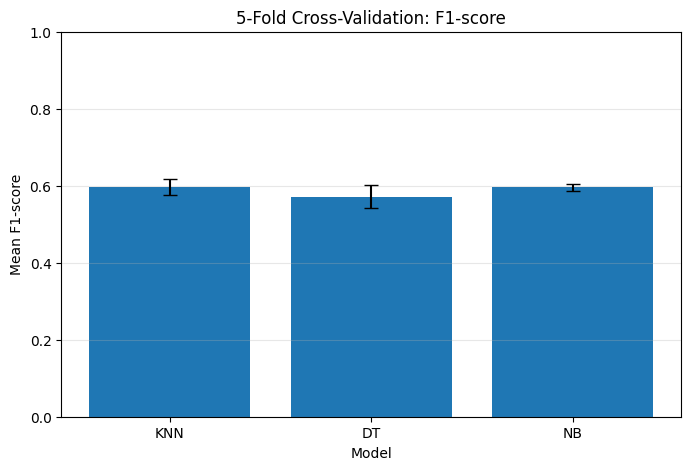

In [212]:
plt.figure(figsize=(8, 5))

plt.bar(
    cv_summary["Model"],
    cv_summary["F1 Mean"],
    yerr=cv_summary["F1 Std"],
    capsize=5
)

plt.title("5-Fold Cross-Validation: F1-score")
plt.xlabel("Model")
plt.ylabel("Mean F1-score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Nhận xét kết quả Cross-validation

Theo output đã lưu, KNN: Precision 0.6126, Recall 0.5819, F1 = 0.5965 ± 0.0196,
ROC-AUC 0.8291. DT balanced: Precision 0.5162, Recall 0.7759, F1 = 0.6194 ± 0.0182,
ROC-AUC 0.8151. NB: Precision 0.4590, Recall 0.8475, F1 = 0.5954 ± 0.0080,
ROC-AUC 0.8221.

Trong output này, DT có F1 cao nhất; KNN có Precision/ROC-AUC cao nhất; NB có Recall
cao nhất và F1 ít dao động nhất. Cần đọc mean/std cùng FP/FN, không có model vượt
trội mọi metric. T9 cần xác nhận các nhận xét. CV sau tuning không phải nested CV.
Hyperparameter và threshold được chọn bằng training; test phục vụ báo cáo đánh giá
cuối cùng và phân tích lỗi, không dùng để điều chỉnh tiếp cấu hình.

## 7. OOF probabilities và cost sensitivity trên training set

In [ ]:
# OOF probabilities: Pipeline fit training folds; validation chỉ transform.
oof_prob_knn = cross_val_predict(
    best_knn, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_prob_dt = cross_val_predict(
    best_dt, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_prob_nb = cross_val_predict(
    best_nb, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

oof_models = {"KNN": oof_prob_knn, "DT": oof_prob_dt, "NB": oof_prob_nb}
for model_name, probabilities in oof_models.items():
    print(model_name, probabilities.shape, probabilities[:5])

In [213]:
best_threshold_knn, threshold_results_knn = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_knn,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

best_threshold_dt, threshold_results_dt = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_dt,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

best_threshold_nb, threshold_results_nb = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_nb,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

In [215]:
locked_thresholds = {
    "KNN": float(best_threshold_knn["Threshold"]),
    "DT": float(best_threshold_dt["Threshold"]),
    "NB": float(best_threshold_nb["Threshold"])
}

print("Locked thresholds:", locked_thresholds)

Locked thresholds: {'KNN': 0.2, 'Decision Tree': 0.25000000000000006, 'Naive Bayes': 0.8900000000000002}


In [216]:
print("===== BEST COST-SENSITIVE THRESHOLDS =====")

print(
    f"KNN: {best_threshold_knn['Threshold']:.2f} "
    f"| Cost: {best_threshold_knn['Cost']:.0f} "
    f"| FP: {best_threshold_knn['FP']:.0f} "
    f"| FN: {best_threshold_knn['FN']:.0f} "
    f"| Recall: {best_threshold_knn['Recall']:.4f} "
    f"| F1: {best_threshold_knn['F1']:.4f}"
)

print(
    f"DT : {best_threshold_dt['Threshold']:.2f} "
    f"| Cost: {best_threshold_dt['Cost']:.0f} "
    f"| FP: {best_threshold_dt['FP']:.0f} "
    f"| FN: {best_threshold_dt['FN']:.0f} "
    f"| Recall: {best_threshold_dt['Recall']:.4f} "
    f"| F1: {best_threshold_dt['F1']:.4f}"
)

print(
    f"NB : {best_threshold_nb['Threshold']:.2f} "
    f"| Cost: {best_threshold_nb['Cost']:.0f} "
    f"| FP: {best_threshold_nb['FP']:.0f} "
    f"| FN: {best_threshold_nb['FN']:.0f} "
    f"| Recall: {best_threshold_nb['Recall']:.4f} "
    f"| F1: {best_threshold_nb['F1']:.4f}"
)

===== BEST COST-SENSITIVE THRESHOLDS =====
KNN: 0.20 | Cost: 2607 | FP: 1652 | FN: 191 | Recall: 0.8722 | F1: 0.5859
DT : 0.25 | Cost: 2615 | FP: 2110 | FN: 101 | Recall: 0.9324 | F1: 0.5577
NB : 0.89 | Cost: 2608 | FP: 1348 | FN: 252 | Recall: 0.8314 | F1: 0.6084


#### Cost-sensitive threshold selection trên OOF training

locked_thresholds được tạo từ các hàng Cost nhỏ nhất với Cost = 5 × FN + FP.
Fine search giữ lưới 0.05–0.95, bước 0.01. Khi nhiều threshold có cùng Cost,
idxmin() chọn hàng đầu tiên trong lưới tăng dần. Keys KNN/DT/NB khớp test evaluation.
Không gán ngưỡng lịch sử; test chỉ đánh giá các ngưỡng đã khóa.

Sensitivity giữ tỷ lệ 1:1, 2:1, 5:1, 10:1 và threshold_grid đã cấu hình. Lưới coarse
sensitivity khác fine search của locked_thresholds nên ngưỡng có thể khác nhau.
Tất cả lựa chọn dùng OOF training. Expected Net Benefit tối ưu riêng ở phần kế tiếp.

In [ ]:
# Sensitivity trên OOF training; giữ lưới coarse hiện có.
all_cost_sensitivity = []
for model_name, probabilities in oof_models.items():
    for scenario_cost_fn in cost_scenarios:
        results = threshold_analysis(
            y_train_raw, probabilities, thresholds=threshold_grid,
            cost_fn=scenario_cost_fn, cost_fp=1
        )
        best_row = results.loc[results["Total Cost"].idxmin()]
        all_cost_sensitivity.append({
            "Model": model_name,
            "FN:FP Cost Ratio": f"{scenario_cost_fn}:1",
            "Best Threshold": best_row["Threshold"],
            "FP": int(best_row["FP"]), "FN": int(best_row["FN"]),
            "Precision": best_row["Precision"], "Recall": best_row["Recall"],
            "F1": best_row["F1"], "Minimum Cost": best_row["Total Cost"]
        })
cost_sensitivity_table = pd.DataFrame(all_cost_sensitivity)
display(cost_sensitivity_table.round(4))

### Expected Net Benefit — kịch bản riêng trên OOF training

Giả định: RETENTION_COST = 10, SAVED_CUSTOMER_VALUE = 100,
RETENTION_SUCCESS_RATE = 0.30. Đây là minh họa, không phải giá trị thực từ dataset.

Expected Net Benefit = TP × 100 × 0.30 − (TP + FP) × 10.
nb_*_best, nb_*_results và net_benefit_summary tối ưu riêng trên OOF training.
Không ghi đè locked_thresholds của Cost 5:1; không dùng test để chọn threshold;
minimum cost và maximum net benefit là hai mục tiêu khác nhau.

In [214]:
nb_knn_best, nb_knn_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_knn,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

nb_dt_best, nb_dt_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_dt,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

nb_nb_best, nb_nb_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_nb,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

In [217]:
net_benefit_summary = pd.DataFrame([
    {
        "Model": "KNN",
        "Threshold": nb_knn_best["Threshold"],
        "TP": nb_knn_best["TP"],
        "FP": nb_knn_best["FP"],
        "FN": nb_knn_best["FN"],
        "Targeted": nb_knn_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_knn_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_knn_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_knn_best["Net_Benefit"]
    },
    {
        "Model": "Decision Tree",
        "Threshold": nb_dt_best["Threshold"],
        "TP": nb_dt_best["TP"],
        "FP": nb_dt_best["FP"],
        "FN": nb_dt_best["FN"],
        "Targeted": nb_dt_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_dt_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_dt_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_dt_best["Net_Benefit"]
    },
    {
        "Model": "Naive Bayes",
        "Threshold": nb_nb_best["Threshold"],
        "TP": nb_nb_best["TP"],
        "FP": nb_nb_best["FP"],
        "FN": nb_nb_best["FN"],
        "Targeted": nb_nb_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_nb_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_nb_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_nb_best["Net_Benefit"]
    }
])

net_benefit_summary

,Model,Threshold,TP,FP,FN,Targeted,Expected Saved Value,Retention Cost,Expected Net Benefit
0,KNN,0.39,1039.0,827.0,456.0,1866.0,31170.0,18660.0,12510.0
1,Decision Tree,0.48,1160.0,1094.0,335.0,2254.0,34800.0,22540.0,12260.0
2,Naive Bayes,0.94,1229.0,1294.0,266.0,2523.0,36870.0,25230.0,11640.0


## 8. Test evaluation: baseline, tuned và cost-sensitive

Các tuned Pipelines đã được refit bằng training sau GridSearchCV.
Phần này đánh giá baseline/tuned và cost-sensitive thresholds đã khóa bằng OOF
training. Test không chạy tuning hoặc threshold search.

### 8.1. KNN: baseline và tuned

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332
ROC-AUC  : 0.7821

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


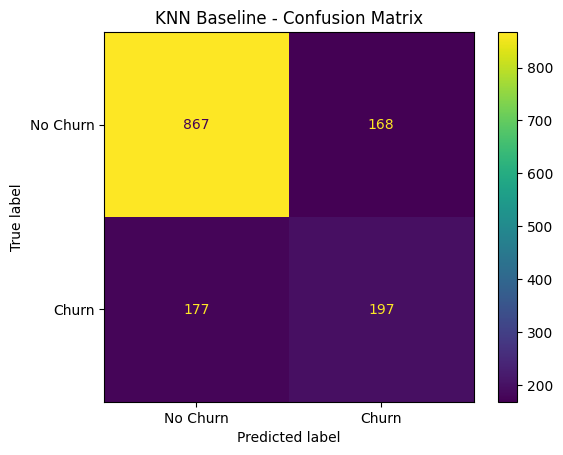

In [218]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

knn_baseline_result = evaluate_model( # danh gia mo hinh 
  y_test, 
  y_predict_knn_baseline, 
  y_proba_km, 
"KNN Baseline")

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

---

>  *Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ*

In [219]:
y_predict_knn_tuned = best_knn.predict(X_test_raw)
y_prob_knn_tuned = best_knn.predict_proba(X_test_raw)[:, 1]

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884
ROC-AUC  : 0.8240

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


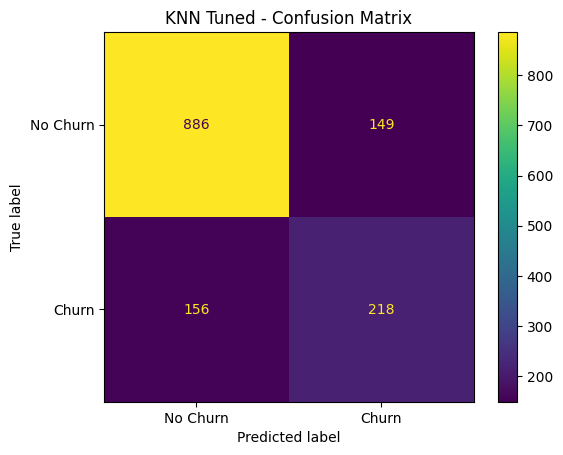

In [220]:
knn_tuned_result = evaluate_model( # danh gia mo hinh 
    y_test,
    y_predict_knn_tuned,
    y_prob_knn_tuned,
    "KNN Tuned"
)

#### Nhận xét

Sau khi tối ưu siêu tham số với `n_neighbors = 21`, mô hình KNN đạt:

- **Accuracy = 78.35%**: mô hình dự đoán đúng khoảng 78% khách hàng.
- **Precision = 59.40%**: trong số khách hàng được dự đoán là Churn,
  khoảng 59% thực sự rời bỏ dịch vụ.
- **Recall = 58.29%**: mô hình phát hiện được khoảng 58% khách hàng
  thực sự Churn.
- **F1-score = 58.84%**: cho thấy sự cân bằng giữa Precision và Recall
  đã được cải thiện.
- **ROC-AUC = 82.40%**: mô hình có khả năng phân biệt tương đối tốt
  giữa khách hàng Churn và No Churn.

Từ Confusion Matrix:

- **TN = 886**: dự đoán đúng khách hàng không Churn.
- **FP = 149**: khách hàng không Churn nhưng bị dự đoán là Churn.
- **FN = 156**: khách hàng thực sự Churn nhưng mô hình không phát hiện được.
- **TP = 218**: khách hàng Churn được mô hình phát hiện chính xác.

Mặc dù vẫn còn 156 trường hợp Churn bị bỏ sót, kết quả cho thấy mô hình
KNN sau tối ưu có khả năng nhận diện khách hàng Churn tốt hơn so với
mô hình baseline.

Số liệu dẫn từ output test đã lưu; T9 cần xác nhận, T8 không tính lại.

TN: true negative: mô hình dự đoán đúng + không churn 

FP: false positve: mô hình dự đoán sai + p: churn -> khong churn -> doanh nghiep chinh sach -> phi 
FN: false: mo hinh du doan k churn -> thuc te churn: doanh nghiep k có chính sách => mất khách 

FN thấp  trade-off: 5:1 => cost 
FP cao => tha bat nham con hon bo sot 

TP 

In [221]:
knn_metrics_comparison = compare_model_metrics(
    knn_baseline_result,
    knn_tuned_result
)

print("\nKNN Metrics Comparison:")
print(knn_metrics_comparison)

knn_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_knn_baseline,
    y_predict_knn_tuned
)

print("\nKNN Confusion Matrix Comparison:")
print(knn_confusion_comparison)


KNN Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7551  0.7835       0.0284
Precision    0.5397  0.5940       0.0543
Recall       0.5267  0.5829       0.0561
F1-score     0.5332  0.5884       0.0552
ROC-AUC      0.7821  0.8240       0.0418

KNN Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       867    886      19
FP       168    149     -19
FN       177    156     -21
TP       197    218      21


#### Kết luận so sánh

KNN Tuned (`k = 21`) cho kết quả tốt hơn KNN Baseline (`k = 5`)
trên toàn bộ các chỉ số đánh giá.

- Accuracy tăng từ **75.51% lên 78.35%**.
- Precision tăng từ **53.97% lên 59.40%**.
- Recall tăng từ **52.67% lên 58.29%**.
- F1-score tăng từ **53.32% lên 58.84%**.
- ROC-AUC tăng từ **78.21% lên 82.40%**.

Đối với lớp Churn, số True Positive tăng từ **197 lên 218**,
trong khi False Negative giảm từ **177 xuống 156**. Như vậy,
mô hình sau tối ưu phát hiện thêm 21 khách hàng Churn và giảm
21 trường hợp Churn bị bỏ sót trên tập test.

Kết quả cho thấy việc tối ưu `n_neighbors` đã cải thiện khả năng
dự đoán của KNN. Vì vậy, KNN Tuned với `k = 21` được chọn làm
phiên bản KNN cuối cùng để so sánh với Decision Tree và Naive Bayes.

So sánh dựa trên outputs đã lưu; T9 cần xác nhận sau cleanup.

### 8.2. Decision Tree: baseline và tuned

===== Desicion Tree Baseline =====
Accuracy : 0.7211
Precision: 0.4753
Recall   : 0.4893
F1-score : 0.4822
ROC-AUC  : 0.6468

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1035
           1       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409

Confusion Matrix:
[[833 202]
 [191 183]]


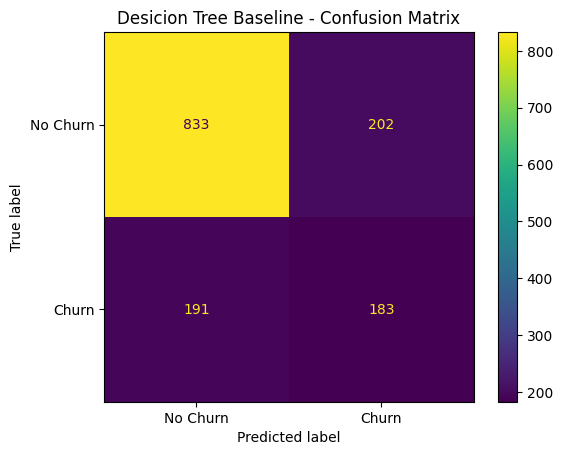

In [222]:
y_predict_dt_baseline = dt_baseline.predict(X_test)
y_prob_dt_baseline =  dt_baseline.predict_proba(X_test)[:,1]

dt_baseline_result = evaluate_model(
  y_test,
  y_predict_dt_baseline,
  y_prob_dt_baseline,
  "Decision Tree Baseline"
)

#### Nhận xét

Decision Tree Baseline đạt:

- **Accuracy = 72.11%**
- **Precision = 47.53%**
- **Recall = 48.93%**
- **F1-score = 48.22%**
- **ROC-AUC = 64.68%**

Confusion Matrix cho thấy mô hình phát hiện đúng **183** khách hàng Churn,
nhưng đồng thời bỏ sót **191** trường hợp Churn (False Negative).

Kết quả baseline cho thấy khả năng nhận diện lớp Churn còn hạn chế.
Đặc biệt, Decision Tree với cấu hình mặc định có thể tạo cây quá phức tạp
do không giới hạn `max_depth`, làm tăng nguy cơ overfitting.

Kết quả này là cơ sở để so sánh với cây đã được kiểm soát độ phức tạp
bằng hyperparameter tuning ở mục 5.2.

Số liệu nhận xét được đồng bộ với output baseline đã lưu; không phải kết quả huấn luyện mới.

In [223]:
y_predict_dt_tuned = best_dt.predict(X_test_raw)
y_prob_dt_tuned = best_dt.predict_proba(X_test_raw)[:, 1]

===== Decision Tree Tuned =====
Accuracy : 0.7459
Precision: 0.5140
Recall   : 0.7834
F1-score : 0.6208
ROC-AUC  : 0.8144

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409

Confusion Matrix:
[[758 277]
 [ 81 293]]


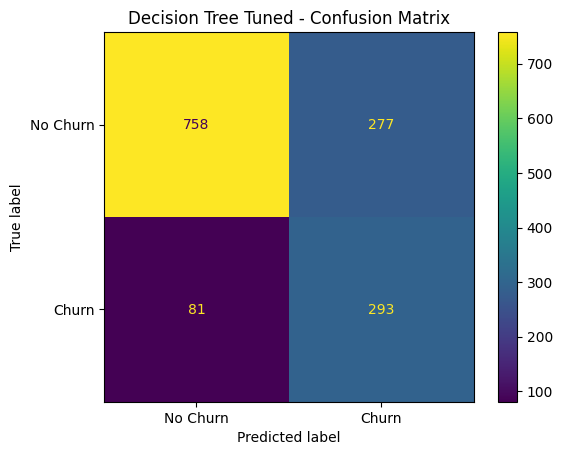

In [224]:
dt_tuned_result = evaluate_model(
  y_test,
  y_predict_dt_tuned,
  y_prob_dt_tuned,
  "Decision Tree Tuned"
)

In [225]:
dt_metrics_comparison = compare_model_metrics(
    dt_baseline_result,
    dt_tuned_result
)

print("\nDecision Tree Metrics Comparison:")
print(dt_metrics_comparison)

dt_confusion_comparison = compare_confusion_matrix(
    y_test, 
    y_predict_dt_baseline,
    y_predict_dt_tuned
)

print("\nDecision Tree Confusion Matrix Comparison:")
print(dt_confusion_comparison)


Decision Tree Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7211  0.7459       0.0248
Precision    0.4753  0.5140       0.0387
Recall       0.4893  0.7834       0.2941
F1-score     0.4822  0.6208       0.1385
ROC-AUC      0.6468  0.8144       0.1676

Decision Tree Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       833    758     -75
FP       202    277      75
FN       191     81    -110
TP       183    293     110


### 8.3. Naive Bayes: baseline và tuned

===== Naive Bayes Baseline =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


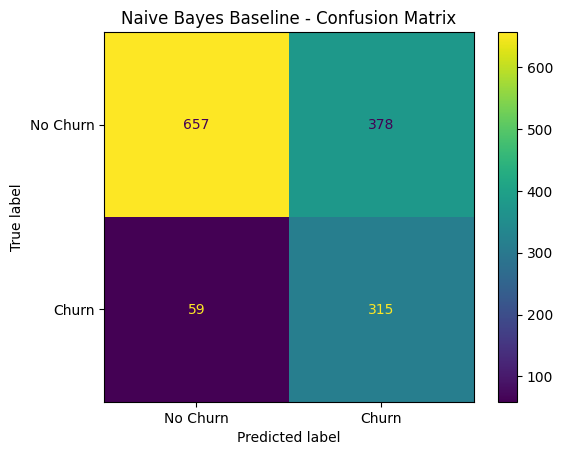

In [226]:
y_predict_nb_baseline = nb_baseline.predict(X_test)
y_prob_nb_baseline = nb_baseline.predict_proba(X_test)[:,1]

nb_baseline_result = evaluate_model(
    y_test,
    y_predict_nb_baseline,
    y_prob_nb_baseline,
    "Naive Bayes Baseline"
)

#### Nhận xét kết quả Baseline

Mô hình Gaussian Naive Bayes Baseline đạt Accuracy = 68.99%, F1-score = 59.04% và ROC-AUC = 80.93%.

Điểm nổi bật của mô hình là Recall đạt 84.22%. Trong tổng số 374 khách hàng thực sự rời bỏ dịch vụ (Churn), mô hình dự đoán đúng 315 khách hàng và chỉ bỏ sót 59 khách hàng (False Negative). Điều này cho thấy mô hình có khả năng phát hiện khách hàng có nguy cơ rời bỏ khá tốt.

Tuy nhiên, Precision chỉ đạt 45.45%. Mô hình dự đoán nhầm 378 khách hàng không Churn thành Churn (False Positive), cho thấy số lượng cảnh báo sai còn tương đối cao.

Nhìn chung, Naive Bayes Baseline có xu hướng ưu tiên phát hiện nhiều khách hàng Churn, giúp giảm số trường hợp bỏ sót khách hàng có nguy cơ rời bỏ, nhưng phải đánh đổi bằng việc gia tăng số lượng False Positive. Trong bối cảnh kinh doanh, điều này có thể giúp doanh nghiệp hạn chế bỏ sót khách hàng cần giữ chân, nhưng đồng thời có thể làm tăng chi phí nếu triển khai chương trình giữ chân cho những khách hàng thực tế không có ý định rời bỏ.

In [227]:
y_predict_nb_tuned = best_nb.predict(X_test_raw)
y_prob_nb_tuned = best_nb.predict_proba(X_test_raw)[:, 1]

===== Naive Bayes Tuned =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8094

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


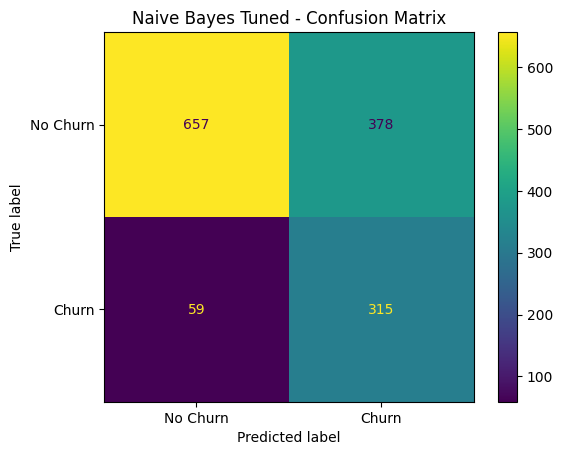

In [228]:
nb_tuned_result = evaluate_model(
    y_test, 
    y_predict_nb_tuned,
    y_prob_nb_tuned,
    "Naive Bayes Tuned"
)

#### Nhận xét sau Hyperparameter Tuning

GridSearchCV khảo sát np.logspace(-12, -1, 12); output tuning đã lưu chọn
var_smoothing = 0.001, Best CV F1-score = 0.5956.

Theo outputs test đã lưu, NB Tuned có Accuracy 0.6899, Precision 0.4545, Recall
0.8422, F1-score 0.5904, ROC-AUC 0.8094; baseline ROC-AUC là 0.8093. Confusion
matrices đã lưu có cùng 657 TN, 378 FP, 59 FN, 315 TP. Nhãn tại ngưỡng mặc định
có thể giữ nguyên dù xác suất/AUC thay đổi nhẹ.

NB có Recall cao và nhiều FP trong outputs này. Cần đọc nb_tuning_results, xác
suất, CV và test metrics; T9 cần xác nhận outputs thuộc đúng cấu hình hiện tại.

In [229]:
nb_metrics_comparison = compare_model_metrics(
    nb_baseline_result,
    nb_tuned_result
)

print("\nNaive Bayes Metrics Comparison:")
print(nb_metrics_comparison)

nb_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_nb_baseline,
    y_predict_nb_tuned
)

print("\nNaive Bayes Confusion Matrix Comparison:")
print(nb_confusion_comparison)


Naive Bayes Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.6899  0.6899       0.0000
Precision    0.4545  0.4545       0.0000
Recall       0.8422  0.8422       0.0000
F1-score     0.5904  0.5904       0.0000
ROC-AUC      0.8093  0.8094       0.0001

Naive Bayes Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       657    657       0
FP       378    378       0
FN        59     59       0
TP       315    315       0


### 8.4. So sánh ba tuned models

In [230]:
final_model_comparison = pd.DataFrame([
    knn_tuned_result,
    dt_tuned_result,
    nb_tuned_result
])

final_model_comparison = final_model_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ]
]

final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN Tuned,0.7835,0.5940,0.5829,0.5884,0.8240
1,Decision Tree Tuned,0.7459,0.5140,0.7834,0.6208,0.8144
2,Naive Bayes Tuned,0.6899,0.4545,0.8422,0.5904,0.8094


#### So sánh kết quả test và CV

Theo outputs đã lưu:

- DT balanced: Accuracy 0.7459, Precision 0.5140, Recall 0.7834, F1 0.6208,
  ROC-AUC 0.8144; CV F1 0.6194 ± 0.0182, ROC-AUC Mean 0.8151.
- KNN Tuned: Accuracy 0.7835, Precision 0.5940, Recall 0.5829, F1 0.5884,
  ROC-AUC 0.8240; CV F1 0.5965 ± 0.0196.
- NB Tuned: Accuracy 0.6899, Precision 0.4545, Recall 0.8422, F1 0.5904,
  ROC-AUC 0.8094; CV F1 0.5954 ± 0.0080.

KNN có Accuracy/Precision/ROC-AUC test cao nhất, DT có F1 cao nhất, NB có Recall
cao nhất trong outputs này. T9 cần xác nhận/đồng bộ. Chênh lệch điểm không tự chứng
minh ưu thế thống kê. Không dùng test để tuning tiếp.

In [231]:
# Tái sử dụng probabilities đã tính; không predict_proba lần thứ hai.
test_probabilities = {
    "KNN": y_prob_knn_tuned, "DT": y_prob_dt_tuned, "NB": y_prob_nb_tuned
}
test_predictions = {
    "KNN": y_predict_knn_tuned, "DT": y_predict_dt_tuned, "NB": y_predict_nb_tuned
}
error_rows = []
for model_name, predictions in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    error_rows.append({"Model": model_name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
error_comparison = pd.DataFrame(error_rows)
display(error_comparison)

,Model,TN,FP,FN,TP
0,KNN,886,149,156,218
1,DT,758,277,81,293
2,NB,657,378,59,315


#### Nhận xét Error Analysis

Theo confusion matrices đã lưu:

- KNN: 149 FP, 156 FN, 218 TP.
- DT balanced: 277 FP, 81 FN, 293 TP.
- NB: 378 FP, 59 FN, 315 TP.

DT balanced phát hiện nhiều churn hơn KNN nhưng tạo nhiều FP hơn. NB có ít FN
nhất/nhiều FP nhất; KNN có ít FP nhất trong outputs này. Cần đọc chi phí giả định
của từng lỗi; không áp dụng kết luận DT chưa weighted cho cấu hình balanced.
T9 cần xác nhận error_comparison.

### 8.5. Đánh giá threshold đã khóa

In [232]:
threshold_test_rows = []
for model_name, probabilities in test_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)
    for setting, threshold in [
        ("Default", 0.50), ("Cost-sensitive", locked_thresholds[model_name])
    ]:
        threshold_test_rows.append({
            "Model": model_name, "Setting": setting,
            **metrics_at_threshold(
                y_test, probabilities, threshold, cost_fn_test, cost_fp_test
            ),
            "ROC-AUC": auc
        })
default_vs_cost = pd.DataFrame(threshold_test_rows)
display(default_vs_cost.round(4))

KeyError: 'DT'

Threshold mặc định là 0.50. Cost-sensitive prediction dùng probability >=
locked_thresholds[model_name]. Cost 5:1 được tính từ confusion matrix: 5 * FN + FP.

#### Cost-sensitive Threshold Analysis

FP có thể làm phát sinh retention không cần thiết; FN có thể làm bỏ lỡ khách hàng
churn. Đây là ý nghĩa minh họa, không phải chi phí thực tế từ dataset.

Sensitivity ở mục 7 xét FN:FP = 1:1, 2:1, 5:1, 10:1 trên OOF training. Test dùng
locked_thresholds tối ưu riêng cho Cost = 5 × FN + FP và so sánh với threshold
0.50 qua default_vs_cost. Ngưỡng khóa trước khi đọc test outcomes.

Không giả định cost test chắc chắn giảm: T9 cần đọc FP/FN, Recall, F1 và Total Cost
trong output mới. Minimum cost OOF không bảo đảm tối ưu cho test hoặc thực tế.
Expected Net Benefit dùng mục tiêu/giả định riêng, không ghi đè cost thresholds.

## 9. Error analysis

#### Error Analysis

Bên cạnh các chỉ số Precision, Recall, F1-score và ROC-AUC, việc phân tích các trường hợp dự đoán sai giúp hiểu rõ hơn hành vi của từng mô hình.

Trong bài toán Customer Churn, hai loại lỗi quan trọng là:

- **False Positive (FP):** Khách hàng thực tế không Churn nhưng mô hình dự đoán Churn. Điều này có thể dẫn đến việc doanh nghiệp triển khai các chương trình giữ chân không cần thiết.
- **False Negative (FN):** Khách hàng thực tế Churn nhưng mô hình dự đoán No Churn. Điều này khiến doanh nghiệp có nguy cơ bỏ sót khách hàng cần được giữ chân.

Do đó, Confusion Matrix của ba mô hình tuned được so sánh để đánh giá sự đánh đổi giữa False Positive và False Negative.

In [ ]:
error_analysis = X_test_raw.reset_index(drop=True).copy()
error_analysis["Actual_Churn"] = np.asarray(y_test).ravel()
for model_name, predictions in test_predictions.items():
    error_analysis[f"{model_name}_Prediction"] = predictions
    error_analysis[f"{model_name}_Result"] = [
        classify_prediction(actual, predicted)
        for actual, predicted in zip(error_analysis["Actual_Churn"], predictions)
    ]
display(error_analysis.head())

In [ ]:
numeric_error_profiles = {}
for model_name in test_predictions:
    profile = (
        error_analysis.groupby(f"{model_name}_Result")[numeric_features]
        .mean().round(2)
    )
    numeric_error_profiles[model_name] = profile
    print(f"\n===== {model_name} =====")
    print(profile.loc[["FP", "FN"]])

for model_name in test_predictions:
    print(f"\n===== {model_name} =====")
    for feature in categorical_features:
        print(f"\n{feature}")
        print(categorical_error_profile(
            error_analysis, feature, f"{model_name}_Result",
            groups=["FP", "FN"], decimals=1
        ))

In [ ]:
segment_results = []

for model in ["KNN", "DT", "NB"]:

    for feature in categorical_features:

        result = segment_error_rate(
            error_analysis,
            model,
            feature
        )

        result.insert(0, "Feature", feature)
        result.insert(0, "Model", model)

        # Đổi tên category thành một cột chung
        result = result.rename(
            columns={feature: "Category"}
        )

        segment_results.append(result)

business_error_summary = pd.concat(
    segment_results,
    ignore_index=True
)

display(business_error_summary.round(4))
# Bảng Contract lấy từ cùng nguồn, không tính lại segment_error_rate.
for model_name in test_predictions:
    print(f"\n===== {model_name} - Contract =====")
    display(business_error_summary.loc[
        (business_error_summary["Model"] == model_name)
        & (business_error_summary["Feature"] == "Contract")
    ].round(4))

#### Phân tích lỗi theo loại hợp đồng (Contract)

business_error_summary cung cấp số mẫu, FP/FN và tỷ lệ lỗi theo Contract cho từng
model. Cần đọc số lượng cùng tỷ lệ, nhất là One year/Two year khi ít mẫu churn.
Các tỷ lệ DT chưa weighted trước đây không đại diện cho DT balanced hiện tại;
T9 cần xác nhận lại các số liệu theo nhóm từ output mới.

#### Business Interpretation of Model Errors

Giữ phân tích Contract, InternetService, PaymentMethod, TechSupport, OnlineSecurity
để nhận diện nhóm có nhiều FN/FP. FN phản ánh churn có thể bị bỏ lỡ; FP phản ánh
can thiệp không cần thiết. Tỷ lệ lỗi cao là tín hiệu xem xét chất lượng mô hình,
không chứng minh quan hệ nhân quả.

DT balanced thay đổi trade-off phát hiện churn/cảnh báo sai. NB/KNN cũng cần đọc
theo bảng lỗi hiện tại. Đề xuất retention cần chi phí thực và quy mô từng nhóm;
phân tích test phục vụ báo cáo, không dùng để tuning hoặc chọn lại threshold.

### Phân tích sâu Decision Tree: FN–TP và FP–TN

In [ ]:
# Giữ quy tắc >= 0.5 của phân tích DT gốc, kể cả trường hợp xác suất đúng 0.5.
y_pred_dt_default = (test_probabilities["DT"] >= 0.5).astype(int)
error_df = error_analysis[list(X_test_raw.columns) + ["Actual_Churn"]].copy()
error_df["Predicted_Churn"] = y_pred_dt_default
error_df["Churn_Probability"] = test_probabilities["DT"]
error_df["Error_Type"] = [
    classify_prediction(actual, predicted)
    for actual, predicted in zip(error_df["Actual_Churn"], y_pred_dt_default)
]
display(error_df["Error_Type"].value_counts())
print("False Negatives :", (error_df["Error_Type"] == "FN").sum())
print("False Positives :", (error_df["Error_Type"] == "FP").sum())

# Chỉ dùng chung thống kê khi predictions thực sự giống nhau.
if np.array_equal(y_pred_dt_default, test_predictions["DT"]):
    error_numeric_summary = numeric_error_profiles["DT"].copy()
    error_numeric_summary.index.name = "Error_Type"
else:
    error_numeric_summary = (
        error_df.groupby("Error_Type")[numeric_features].mean().round(2)
    )
display(error_numeric_summary)

In [ ]:
contract_error_profile = categorical_error_profile(
    error_df,
    "Contract"
)

display(contract_error_profile)

internet_error_profile = categorical_error_profile(
    error_df,
    "InternetService"
)

display(internet_error_profile)

#### Phân tích đặc điểm các trường hợp dự đoán sai

**False Negative (FN) so với True Positive (TP)**

Cả FN và TP là khách hàng thực tế churn. So sánh tenure, MonthlyCharges,
TotalCharges và Contract/InternetService trong các bảng profile giúp nhận diện
nhóm bị bỏ sót so với nhóm được phát hiện. Số liệu cụ thể cần lấy từ output DT
balanced hiện tại và được T9 xác nhận.

**False Positive (FP) so với True Negative (TN)**

Cả FP và TN là khách hàng thực tế không churn. So sánh các nhóm giúp xem profile
nào thường bị cảnh báo nhầm và profile nào được phân loại đúng. Cần đọc cả số mẫu
và tỷ lệ; nhóm nhỏ có thể tạo tỷ lệ biến động lớn. Các bảng numeric/categorical
error profiles được giữ; quan hệ quan sát không chứng minh quan hệ nhân quả.

#### Liên hệ với Cost-sensitive Threshold

Threshold DT 5:1 là locked_thresholds["DT"], được chọn bằng OOF training.
default_vs_cost báo FP/FN và Cost test tại ngưỡng mặc định và ngưỡng khóa. Giảm
ngưỡng thường giảm FN nhưng tăng FP; T9 cần đọc trade-off thực tế trong output.
Chi phí 5:1 là giả định, không khẳng định một ngưỡng tối ưu tuyệt đối cho doanh nghiệp.

## 10. Feature importance và driver insights

Decision Tree Tuned được lựa chọn làm mô hình đại diện cho driver-based analysis
do mô hình cung cấp feature importance trực tiếp và có cấu trúc quyết định dễ diễn giải.

Việc lựa chọn Decision Tree trong phần này nhằm phục vụ mục tiêu explainability,
không hàm ý Decision Tree là mô hình dự đoán tốt nhất trong mọi tiêu chí.

KNN và Naive Bayes vẫn được sử dụng trong phần đánh giá và so sánh hiệu năng mô hình.

#### Feature Importance from Tuned Decision Tree

Decision Tree Tuned được sử dụng để phân tích mức độ quan trọng của các đặc trưng.

Feature importance của Decision Tree phản ánh mức độ mỗi feature đóng góp vào việc
giảm impurity trong quá trình xây dựng cây. Feature có importance cao hơn được mô hình
sử dụng nhiều hơn trong các quyết định phân loại.

Phân tích này được sử dụng để xác định các churn drivers tiềm năng phục vụ bước
phân tích nghiệp vụ tiếp theo.

Lưu ý: Feature importance thể hiện mức độ quan trọng đối với dự đoán của mô hình,
không chứng minh quan hệ nhân quả và cũng không trực tiếp cho biết feature làm tăng
hay giảm xác suất churn.

In [ ]:
feature_importance_df = pd.DataFrame({
    "Feature": best_dt.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": best_dt.named_steps["clf"].feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance_df.head(10)

In [ ]:
top_10_features = (
    feature_importance_df
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Tuned Decision Tree")

plt.tight_layout()
plt.show()

#### Top Churn Drivers and Direction of Association

Feature importance cho biết mức độ Decision Tree sử dụng từng đặc trưng trong quá trình
phân loại, nhưng không cho biết đặc trưng đó liên quan với churn theo hướng nào.

Do đó, đối với các feature quan trọng nhất, nhóm tiếp tục đối chiếu với dữ liệu gốc để
xem xét churn rate theo từng nhóm hoặc theo mức giá trị của feature.

Mục tiêu của bước này là kết hợp:

Feature Importance → Direction of Association → Business Interpretation

Phân tích này mang tính mô tả và giải thích hành vi của mô hình, không được diễn giải
như bằng chứng về quan hệ nhân quả.

In [ ]:
# df_raw["Churn"] đã được mã hóa 0/1 tại mục dữ liệu; không map lại Yes/No.
driver_df = df_raw.copy()
driver_df["Churn_binary"] = driver_df["Churn"]
assert driver_df["Churn_binary"].notna().all()
assert set(driver_df["Churn_binary"].unique()) == {0, 1}

In [ ]:
contract_churn = churn_rate_by_group(driver_df, "Contract", sort_by_rate=True)
internet_churn = churn_rate_by_group(driver_df, "InternetService", sort_by_rate=True)
driver_df["Tenure_Group"] = pd.cut(
    driver_df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)
tenure_churn = churn_rate_by_group(driver_df, "Tenure_Group", observed=True)
driver_df["MonthlyCharges_Group"] = pd.qcut(
    driver_df["MonthlyCharges"], q=4,
    labels=["Q1 - Lowest", "Q2", "Q3", "Q4 - Highest"]
)
monthly_churn = churn_rate_by_group(driver_df, "MonthlyCharges_Group", observed=True)
for driver_table in [contract_churn, internet_churn, tenure_churn, monthly_churn]:
    display(driver_table.round(2))

| Driver                        | DT Importance hiện tại | Quan sát từ dữ liệu                                              |
| ----------------------------- | ------------: | ---------------------------------------------------------------- |
| Contract – Month-to-month     | Xem feature_importance_df | Month-to-month churn **42.71%**, One year 11.27%, Two year 2.83% |
| tenure                        | Xem feature_importance_df | 0–12 tháng **47.44%** → 49–72 tháng chỉ **9.51%**                |
| InternetService – Fiber optic | Xem feature_importance_df | Fiber optic **41.89%**, DSL 18.96%, No Internet 7.40%            |
| MonthlyCharges                | Xem feature_importance_df | Q1 11.24%, Q2 24.58%, **Q3 37.51%**, Q4 32.88%                   |

#### Driver-based Insights & Business Interpretation

Các đặc trưng được đối chiếu gồm Contract_Month-to-month, tenure,
InternetService_Fiber optic và MonthlyCharges. Importance/thứ hạng DT balanced
phải lấy từ feature_importance_df; T9 sẽ xác nhận output mới. Để xác định hướng của các mối liên hệ, nhóm tiếp tục đối chiếu
feature importance với churn rate quan sát được trên dữ liệu gốc.

**1. Contract type**

`Contract_Month-to-month` là đặc trưng hợp đồng được đối chiếu trong phân tích này. Khách hàng sử dụng hợp đồng Month-to-month có churn rate 42.71%,
cao hơn đáng kể so với One year (11.27%) và Two year (2.83%).

Kết quả cho thấy nhóm khách hàng sử dụng hợp đồng ngắn hạn là một phân khúc
có rủi ro churn đáng chú ý. Trong thực tế, doanh nghiệp có thể cân nhắc các chương
trình khuyến khích khách hàng phù hợp chuyển sang hợp đồng dài hạn, chẳng hạn
ưu đãi gia hạn hoặc loyalty benefits.

**2. Customer tenure**

`tenure` được đối chiếu với churn rate theo thời gian gắn bó. Churn rate giảm rõ
rệt khi thời gian gắn bó tăng: khách hàng trong 0–12 tháng có churn rate 47.44%,
trong khi nhóm 49–72 tháng chỉ còn 9.51%.

Điều này cho thấy khách hàng mới là nhóm cần được chú ý trong chiến lược retention.
Doanh nghiệp có thể ưu tiên onboarding, hỗ trợ và các hoạt động chăm sóc trong
những tháng đầu của vòng đời khách hàng.

**3. Internet service**

`InternetService_Fiber optic` được đối chiếu với churn rate theo loại dịch vụ.
Nhóm sử dụng Fiber optic có churn rate 41.89%, so với 18.96% ở DSL và
7.40% ở nhóm không sử dụng Internet Service.

Kết quả xác định khách hàng Fiber optic là một phân khúc có churn rate quan sát
được tương đối cao. Tuy nhiên, phân tích hiện tại chưa xác định nguyên nhân của
sự khác biệt này. Doanh nghiệp có thể xem đây là nhóm cần điều tra thêm về
chất lượng dịch vụ, giá, hỗ trợ kỹ thuật hoặc các yếu tố liên quan trước khi đưa
ra chính sách cụ thể.

**4. Monthly charges**

`MonthlyCharges` được đối chiếu với churn rate theo mức phí. Churn rate tăng từ 11.24% ở quartile
thấp nhất lên 24.58% ở Q2 và đạt 37.51% ở Q3, nhưng giảm nhẹ xuống 32.88%
ở quartile cao nhất.

Do đó, dữ liệu không hỗ trợ kết luận đơn giản rằng MonthlyCharges càng cao thì
churn càng tăng. Thay vào đó, mức phí hàng tháng có mối liên hệ phi tuyến với
churn và có thể tương tác với các yếu tố khác như loại hợp đồng hoặc loại dịch vụ.

**Business interpretation**

Mức độ DT balanced sử dụng các đặc trưng cần đọc từ bảng importance hiện tại. Kết hợp với churn
rate quan sát được, kết quả gợi ý rằng nhóm khách hàng hợp đồng Month-to-month,
khách hàng mới và khách hàng Fiber optic là những phân khúc đáng được doanh
nghiệp theo dõi trong chiến lược retention.

Các kết quả trên phản ánh association trong dataset và hành vi của mô hình,
không chứng minh rằng các đặc trưng này trực tiếp gây ra churn.

## 11. Risk × Value segmentation

Sau khi xác định các churn drivers, nhóm tiếp tục phân tích cách doanh nghiệp có thể
ưu tiên khách hàng khi nguồn lực retention có giới hạn.

Chỉ xác suất churn chưa đủ để xác định mức độ ưu tiên. Hai khách hàng có cùng nguy
cơ churn có thể mang lại giá trị kinh doanh khác nhau.

Do dataset không cung cấp Customer Lifetime Value (CLV) hoặc lợi nhuận thực tế,
`MonthlyCharges` được sử dụng như một proxy đơn giản cho giá trị hiện tại của
khách hàng.

Phân tích kết hợp hai chiều:

- Risk: xác suất churn do mô hình dự đoán.
- Value: MonthlyCharges của khách hàng.

Từ đó khách hàng được phân thành bốn nhóm Risk × Value để hỗ trợ việc xác định
mức độ ưu tiên cho các hoạt động retention.

Lưu ý rằng MonthlyCharges chỉ là proxy cho customer value và không đại diện cho
CLV hoặc lợi nhuận thực tế.

Ta dùng Decision Tree như một minh họa segmentation nhất quán với mục Feature importance, và ghi rõ đây là model dùng cho phân tích minh họa chứ chưa phải tuyên bố deployment model cuối cùng.

In [ ]:
# Khóa cutoff bằng OOF training; không chọn cutoff từ test probabilities.
risk_threshold = np.quantile(oof_prob_dt, 0.70)
print(f"Risk threshold (70th percentile of OOF training): {risk_threshold:.4f}")
# Quy tắc >= giữ nguyên các khách hàng có xác suất đồng hạng tại cutoff.

High Risk: probability ≥ phân vị 70% của oof_prob_dt trên training.
High Value: MonthlyCharges ≥ median MonthlyCharges của X_train_raw.

Chính sách hướng tới khoảng top 30% rủi ro trên phân bố training. DT có xác suất
đồng hạng tại cutoff; dùng >= có thể làm High Risk hơi lớn hơn 30%, đôi khi đáng
kể. Tỷ lệ test cũng có thể khác do phân bố khác training. T9 xác nhận tỷ lệ thực tế.

In [ ]:
value_threshold = X_train_raw["MonthlyCharges"].median()
print(f"Value threshold (training MonthlyCharges median): {value_threshold:.2f}")

Hai người đều trả phí cao nhưng mức độ churn risk hoàn toàn khác nhau. Đây chính là giá trị của segmentation.

In [ ]:
risk_value_df = X_test_raw.copy().reset_index(drop=True)

risk_value_df["Actual_Churn"] = (
    y_test_raw.reset_index(drop=True)
)

risk_value_df["Churn_Probability"] = (
    y_prob_dt_tuned
)

risk_value_df["Risk"] = np.where(
    risk_value_df["Churn_Probability"] >= risk_threshold,
    "High Risk",
    "Low Risk"
)

risk_value_df["Value"] = np.where(
    risk_value_df["MonthlyCharges"] >= value_threshold,
    "High Value",
    "Low Value"
)

risk_value_df["Segment"] = (
    risk_value_df["Risk"]
    + " - "
    + risk_value_df["Value"]
)

risk_value_df[
    [
        "MonthlyCharges",
        "Churn_Probability",
        "Actual_Churn",
        "Risk",
        "Value",
        "Segment"
    ]
].head()

In [ ]:
risk_value_df["At_Risk_Revenue"] = (
    risk_value_df["Churn_Probability"]
    * risk_value_df["MonthlyCharges"]
)

In [ ]:
segment_summary = (
    risk_value_df
    .groupby("Segment")
    .agg(
        Customers=("Segment", "size"),
        Avg_Churn_Probability=(
            "Churn_Probability", "mean"
        ),
        Actual_Churn_Rate=(
            "Actual_Churn", "mean"
        ),
        Avg_MonthlyCharges=(
            "MonthlyCharges", "mean"
        ),
        Total_At_Risk_Revenue=(
            "At_Risk_Revenue", "sum"
        )
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / len(risk_value_df)
    * 100
)

segment_summary = segment_summary[
    [
        "Segment",
        "Customers",
        "Customer_Percentage",
        "Avg_Churn_Probability",
        "Actual_Churn_Rate",
        "Avg_MonthlyCharges",
        "Total_At_Risk_Revenue"
    ]
]

segment_summary

In [ ]:
high_risk_count = (
    risk_value_df["Risk"] == "High Risk"
).sum()

high_risk_pct = (
    high_risk_count
    / len(risk_value_df)
    * 100
)

print(
    f"High-risk customers: "
    f"{high_risk_count}/{len(risk_value_df)} "
    f"({high_risk_pct:.2f}%)"
)

print(
    f"Actual churn rate: "
    f"{risk_value_df['Actual_Churn'].mean():.2%}"
)

print(
    f"Risk threshold: "
    f"{risk_threshold:.4f}"
)

print(
    f"Value threshold: "
    f"{value_threshold:.2f}"
)

#### Business Interpretation

Risk × Value segmentation được xây dựng bằng cách kết hợp xác suất churn dự đoán
từ Decision Tree với MonthlyCharges, được sử dụng như một proxy đơn giản cho
customer value.

Cutoff được xác định trên training trước khi áp dụng lên test: High Value dùng
median MonthlyCharges; High Risk dùng phân vị 70% OOF churn probabilities,
hướng tới khoảng top 30%. DT ties tại cutoff và quy tắc >= có thể làm High Risk
lớn hơn 30%; tỷ lệ test còn phụ thuộc phân bố của tập này.

segment_summary giữ Customers, Customer_Percentage, Avg_Churn_Probability,
Actual_Churn_Rate, Avg_MonthlyCharges và Total_At_Risk_Revenue.
At_Risk_Revenue = Churn_Probability × MonthlyCharges là chỉ báo trọng số rủi ro,
không phải doanh thu mất đi thực tế. Actual_Churn_Rate được báo cáo từ nhãn test
sau khi khóa cutoff, không dùng chọn cutoff. T9 sẽ xác nhận số lượng/tỷ lệ mới.

Trong bối cảnh nguồn lực retention có giới hạn, nhóm High Risk × High Value là
một phân khúc đặc biệt đáng chú ý vì kết hợp đồng thời churn risk dự đoán cao
và MonthlyCharges cao. Các khách hàng này có thể được xem xét cho các chương
trình retention có mục tiêu.

Nhóm High Risk × Low Value cũng có churn risk tương đối cao, nhưng quyết định
can thiệp cần cân nhắc chi phí retention so với giá trị kinh doanh kỳ vọng.

Ngược lại, nhóm Low Risk × High Value có giá trị proxy cao nhưng churn risk
dự đoán thấp. Nhóm này có thể phù hợp hơn với các hoạt động duy trì trải nghiệm
và loyalty thay vì các biện pháp retention khẩn cấp.

Nhóm Low Risk × Low Value có cả churn risk và customer value proxy tương đối
thấp, do đó có thể được quản lý bằng các chiến lược chăm sóc có chi phí thấp
hoặc tự động hóa.

Cần lưu ý rằng MonthlyCharges chỉ phản ánh doanh thu hàng tháng và không phải
Customer Lifetime Value (CLV) hoặc lợi nhuận thực tế. Vì vậy, Risk × Value
segmentation trong phân tích này nên được xem là một framework hỗ trợ ra quyết
định thay vì một chính sách phân bổ ngân sách retention hoàn chỉnh.

## 12. Tổng hợp và giới hạn

| Model | Điểm mạnh theo outputs đã lưu | Hạn chế |
| --- | --- | --- |
| KNN | Precision test 0.5940, ROC-AUC 0.8240; ít FP hơn DT/NB | Nhạy scaling; chi phí prediction tăng theo training size; Recall 0.5829 |
| DT balanced | Độ sâu 3 dễ diễn giải; F1 test 0.6208, Recall 0.7834 | Nhiều FP hơn KNN; phụ thuộc cấu hình/class weighting |
| Naive Bayes | Recall test 0.8422; nhanh; tuning chọn var_smoothing 0.001 | Precision 0.4545 và nhiều FP; giả định độc lập có điều kiện |

Giá trị dẫn từ outputs đã lưu, chưa tính lại trong T8; T9 cần đồng bộ.

#### Kết luận so sánh mô hình

Theo outputs đã lưu, KNN có Accuracy/Precision/ROC-AUC test cao nhất; DT balanced
có F1 test cao nhất; NB có Recall test cao nhất. Không có model vượt trội trên mọi
tiêu chí. T9 cần xác nhận sau cleanup.

Cost-sensitive analysis chọn threshold từ OOF training để giảm 5 × FN + FP.
Expected Net Benefit tối ưu riêng với retention cost 10, saved customer value 100,
success rate 0.30; đây là giả định minh họa, không phải giá trị thực từ dataset.
Risk × Value giữ phân vị 70% OOF và median MonthlyCharges của training.

Sự phù hợp model phụ thuộc mục tiêu, FP/FN, chi phí và khả năng diễn giải.
MonthlyCharges là proxy, không phải CLV. Test phục vụ báo cáo đánh giá cuối cùng,
không để chọn lại cấu hình hoặc threshold.

### Giới hạn và runtime checks cho T9

- Tuning/CV/OOF dùng raw training qua Pipeline; preprocessing chỉ fit training
  portion tương ứng. Baselines giữ processed artifacts.
- CV sau tuning không phải nested CV. GridSearch cv=5 và CV/OOF shuffle seed 42
  giữ nguyên; OOF sau tuning không phải nested evaluation độc lập.
- Cost thresholds chỉ lấy từ OOF training. Net Benefit có thresholds/results
  riêng, không ghi đè locked_thresholds.
- DT grid có class_weight [None, "balanced"]; output chọn balanced/gini/depth 3/
  leaf 1/split 2. NB grid np.logspace(-12, -1, 12), output chọn 0.001.
- Risk cutoff là phân vị 70% OOF training; ties có thể làm High Risk vượt 30%.
  Value cutoff là training MonthlyCharges median; MonthlyCharges không phải CLV.
- Net Benefit dùng giả định 10/100/0.30, không phải business data thực tế.
- Driver rates là mô tả toàn dataset. Importance/error profiles không chứng minh
  quan hệ nhân quả. Tỷ lệ lỗi cần đọc cùng số mẫu; segment_error_rate giữ quy ước
  trả 0 khi mẫu số bằng 0.
- T8 chỉ static cleanup, giữ outputs/counts. T9 cần xác nhận execution order,
  tuning/CV/OOF, predict_proba, thresholds/results, feature importance, plots và
  số liệu markdown; kiểm tra sklearn tương thích preprocessing artifact.
  Không dùng test/error analysis để tuning tiếp.